# 2. Entrenamiento del modelo — Deteccion de fraude

Problema: **clasificacion binaria supervisada** (`isFraud`), fuertemente
desbalanceado (~0.1-0.3% de positivos).

> **Nota de computo:** la referencia completa tiene ~5.8M filas; en el
> equipo de desarrollo de este proyecto eso no corre en un tiempo
> razonable (una sola comparacion de 5-fold CV con RandomForest supero
> la hora sin terminar). Se trabaja sobre una **submuestra estratificada
> de 1.8M filas** (manteniendo la tasa real de fraude), que si es viable
> en este hardware. Ver seccion de limitaciones en el `README.md`
> principal. Produccion (evaluacion online) se usa completa, sin
> submuestrear.

Flujo:
1. Train/test split estratificado sobre la **referencia** (`step <= 400`,
   submuestreada por limite de computo, ver nota arriba).
2. **Balanceo de clases** con las tecnicas vistas en la Sesion 8 del curso
   (Reweighing y Oversampling), generalizadas de "equilibrar un grupo
   sensible" a "equilibrar la clase minoritaria del target".
3. Modelo base (Logistic Regression) como piso de comparacion.
4. Optimizacion de hiperparametros de un `XGBoostClassifier` con
   **Random Search** (`RandomizedSearchCV`, Sesion 3).
5. Registro de experimentos (parametros, metricas, artefactos) en **MLflow**.
6. Evaluacion **offline** (holdout de referencia) y **online** (datos de
   produccion `step > 400`, que en este dataset simulado si tienen
   `isFraud` real, permitiendo medir el desempeno "como si" ya estuviera
   desplegado).

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from xgboost import XGBClassifier

from src.balancing import oversample_minority, reweighting_sample_weights
from src.config import (
    MODEL_DIR,
    PROCESSED_DTYPES,
    MODEL_PATH,
    PRODUCTION_DATA_PATH,
    RANDOM_STATE,
    REFERENCE_DATA_PATH,
    TARGET_COL,
)
from src.features import select_model_features
from src.metrics import classification_metrics
from src.tracking import init_mlflow, log_classification_metrics

MODEL_DIR.mkdir(parents=True, exist_ok=True)
init_mlflow()


2026/10/27 21:28:59 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\venvs\dsrp_fraud\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [2]:
reference = pd.read_csv(REFERENCE_DATA_PATH, dtype=PROCESSED_DTYPES)
production = pd.read_csv(PRODUCTION_DATA_PATH, dtype=PROCESSED_DTYPES)
print(f"Referencia completa: {reference.shape} | tasa de fraude = {reference[TARGET_COL].mean():.5%}")

# Limite de computo: la referencia completa (~5.8M filas) no corre en un
# tiempo razonable en el equipo de desarrollo de este proyecto (una sola
# corrida de 5-fold CV con RandomForest tardo mas de una hora sin terminar).
# Se usa una submuestra estratificada grande (mantiene la tasa real de
# fraude via stratify, no se fuerza ningun balance artificial aqui -- eso
# se decide mas abajo en 2.1) como compromiso explicito entre robustez
# estadistica y tiempo de entrenamiento. Documentado en el README.
MAX_REFERENCE_ROWS = 1_800_000
if len(reference) > MAX_REFERENCE_ROWS:
    reference, _ = train_test_split(
        reference,
        train_size=MAX_REFERENCE_ROWS,
        stratify=reference[TARGET_COL],
        random_state=RANDOM_STATE,
    )
    reference = reference.reset_index(drop=True)
    print(f"Referencia submuestreada: {reference.shape} | tasa de fraude = {reference[TARGET_COL].mean():.5%}")

FEATURES = select_model_features(reference)
print(f"{len(FEATURES)} features:", FEATURES)

X = reference[FEATURES]
y = reference[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

Referencia completa: (5787030, 18) | tasa de fraude = 0.07736%


Referencia submuestreada: (1800000, 18) | tasa de fraude = 0.07739%
16 features: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest', 'amountToOldBalanceOrgRatio', 'origAccountEmptied', 'isDestMerchant', 'destBalanceUnknown', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


(1440000, 16) (360000, 16) 0.0007736111111111111 0.000775


## 2.1 Balanceo de clases (tecnicas de la Sesion 8)

El curso introduce dos tecnicas de *pre-processing* para dar mas peso o
representacion a la clase minoritaria, en el contexto de **fairness**
(equilibrar un grupo demografico sensible):

- **Reweighing** (`mod0_Reweighing.ipynb`): pesos pasados como
  `sample_weight` a `.fit()` (en el notebook original, 2.0 para el grupo
  desfavorecido y 1.0 para el resto).
- **Oversampling** (`mod1_Oversampling.ipynb`): duplicar con reemplazo las
  filas del grupo minoritario via `sklearn.utils.resample`.

Aqui generalizamos exactamente la misma mecanica, pero equilibrando la
clase minoritaria del **target** (`isFraud`) en vez de un grupo sensible
(ver [`src/balancing.py`](../src/balancing.py)). No se usa ninguna libreria
de balanceo externa (p.ej. `imbalanced-learn`/SMOTE) por no haber sido
parte del curso.

Comparamos **Original (sin balanceo)**, **Reweighing** y **Oversampling**
con `RandomForestClassifier` (igual que en los notebooks de la Sesion 8),
promediando PR-AUC/Recall sobre **5-fold `StratifiedKFold`** en vez de un
holdout simple, para que la eleccion de estrategia sea mas robusta.

**Cuidado con la fuga de informacion:** el balanceo se aplica *dentro* de
cada fold de entrenamiento, nunca antes de dividir en folds. Si se
sobremuestreara (oversampling) sobre todo `X_train` y *despues* se hiciera
K-Fold, copias casi identicas de la misma fila original podrian terminar
una en el fold de entrenamiento y otra en el de validacion de la misma
iteracion -> el modelo "ve" en validacion filas casi iguales a las que uso
para entrenar, y las metricas quedan infladas artificialmente. Por eso
`cv_eval_estrategia` recibe los indices de cada fold y construye
`sample_weight`/oversampling solo con la porcion de entrenamiento de esa
fold.

In [3]:
# n_splits=3 y n_estimators=100 (en vez de 5/200): en el equipo de
# desarrollo, 5 folds x 200 arboles x 3 estrategias no termino en una hora
# sobre la submuestra de 1.8M filas (ver nota de computo mas arriba). Esta
# etapa solo necesita un ranking relativo entre estrategias, no precision
# maxima -- se afina el modelo real mas abajo con Random Search.
balancing_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rf_kwargs = dict(n_estimators=100, max_depth=8, random_state=RANDOM_STATE, n_jobs=4)


def cv_eval_estrategia(nombre, build_fold_data):
    """Promedia metricas sobre 5 folds estratificados.

    `build_fold_data(X_tr, y_tr)` debe devolver (X_fit, y_fit, sample_weight)
    aplicando el balanceo SOLO con los datos de la fold de entrenamiento
    (`X_tr`, `y_tr`) -- nunca con el `X_train` completo -- para evitar fuga
    de informacion entre folds (ver nota en la celda de markdown anterior).
    """
    fold_metrics = []
    for train_idx, val_idx in balancing_cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        X_fit, y_fit, sample_weight = build_fold_data(X_tr, y_tr)

        model = RandomForestClassifier(**rf_kwargs)
        model.fit(X_fit, y_fit, sample_weight=sample_weight)

        proba = model.predict_proba(X_val)[:, 1]
        preds = (proba >= 0.5).astype(int)
        fold_metrics.append(classification_metrics(y_val, preds, proba))

    metrics_mean = pd.DataFrame(fold_metrics).mean().to_dict()
    metrics_mean["estrategia"] = nombre
    return metrics_mean


resultados = [
    # --- Original (sin balanceo) ---
    cv_eval_estrategia("Original", lambda X_tr, y_tr: (X_tr, y_tr, None)),
    # --- Reweighing: pesos calculados SOLO con la fold de entrenamiento ---
    cv_eval_estrategia(
        "Reweighing",
        lambda X_tr, y_tr: (X_tr, y_tr, reweighting_sample_weights(y_tr)),
    ),
    # --- Oversampling: se aplica DENTRO de cada fold, nunca antes del split ---
    cv_eval_estrategia(
        "Oversampling",
        lambda X_tr, y_tr: (*oversample_minority(X_tr, y_tr, random_state=RANDOM_STATE), None),
    ),
]

comparacion = pd.DataFrame(resultados).set_index("estrategia")[
    ["precision", "recall", "f1", "pr_auc", "roc_auc"]
]
comparacion

,precision,recall,f1,pr_auc,roc_auc
estrategia,,,,,
Original,1.000000,0.994612,0.997295,0.996068,0.998195
Reweighing,0.984427,0.994612,0.989381,0.996348,0.998898
Oversampling,0.994652,0.994612,0.994616,0.996238,0.998806


**Decision:** seguimos adelante con la estrategia con mejor `pr_auc`
promedio (5-fold CV) en la comparacion anterior.

- Si gana **Reweighing**, la llevamos tal cual a la optimizacion de
  hiperparametros: los pesos se recalculan dentro de cada fold de la
  validacion cruzada de `RandomizedSearchCV` (via `fit_params`), sin
  riesgo de fuga de informacion.
- Si gana **Oversampling**, sobremuestreamos **una sola vez** todo
  `X_train` para construir el set de entrenamiento final. A diferencia de
  la comparacion de arriba (que sí re-aplica oversampling en cada fold),
  aqui `RandomizedSearchCV` recibe el set ya sobremuestreado y hace su
  propia validacion cruzada interna sobre el *(por simplicidad no se
  vuelve a aislar el oversampling por fold en esa etapa; es una limitacion
  conocida de la tecnica que se documenta en las conclusiones).

In [4]:
mejor_estrategia = comparacion["pr_auc"].idxmax()
print("Estrategia de balanceo elegida (promedio 5-fold CV):", mejor_estrategia)

if mejor_estrategia == "Reweighing":
    X_train_bal, y_train_bal = X_train, y_train
    sample_weight_bal = reweighting_sample_weights(y_train)
elif mejor_estrategia == "Oversampling":
    # Oversampling final sobre TODO X_train (una sola vez, no por fold):
    # a partir de aqui es preparacion de datos para el entrenamiento, no
    # evaluacion -- la comparacion de arriba ya evaluo esta estrategia de
    # forma honesta (sin fuga) con oversampling dentro de cada fold.
    X_train_bal, y_train_bal = oversample_minority(X_train, y_train, random_state=RANDOM_STATE)
    sample_weight_bal = None
else:
    X_train_bal, y_train_bal = X_train, y_train
    sample_weight_bal = None

with mlflow.start_run(run_name="class_balancing_comparison"):
    mlflow.log_param("balancing_strategy_chosen", mejor_estrategia)
    for estrategia, row in comparacion.iterrows():
        for metric_name, value in row.items():
            mlflow.log_metric(f"{estrategia.lower()}_{metric_name}", float(value))

Estrategia de balanceo elegida (promedio 5-fold CV): Reweighing


## 2.2 Modelo base (Logistic Regression)

Sirve como piso de comparacion, ya usando la estrategia de balanceo elegida arriba.

In [5]:
with mlflow.start_run(run_name="baseline_logreg"):
    baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    baseline.fit(X_train_bal, y_train_bal, sample_weight=sample_weight_bal)

    proba = baseline.predict_proba(X_test)[:, 1]
    preds = (proba >= 0.5).astype(int)
    metrics = classification_metrics(y_test, preds, proba)

    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("balancing_strategy", mejor_estrategia)
    log_classification_metrics("offline_", metrics)
    print(metrics)

{'accuracy': 0.33974444444444446, 'precision': 0.0011598344294328998, 'recall': 0.989247311827957, 'f1': 0.0023169523681603734, 'roc_auc': 0.7637824481236999, 'pr_auc': 0.030086300399671095, 'log_loss': 0.5574567914009094}


## 2.3 Optimizacion de hiperparametros - XGBoost

Tecnica vista en el curso (Sesion 3): **Random Search** (`RandomizedSearchCV`),
exploracion aleatoria del espacio de hiperparametros (en vez de probar la
grilla completa como Grid Search).

El desbalance de clases ya se maneja con la estrategia elegida en 2.1
(Reweighing u Oversampling) - no se usa `scale_pos_weight` ni
`class_weight` (no vistos en el curso).


In [6]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Espacio acotado (n_estimators <= 400, n_iter=10 en vez de 15) por limite
# de computo del equipo de desarrollo -- ver nota de computo al inicio del
# notebook.
param_dist = {
    "n_estimators": [150, 200, 300, 400],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

base_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=4,
)

fit_params = {"sample_weight": sample_weight_bal} if sample_weight_bal is not None else {}

# n_jobs=1 en el search (secuencial): cada candidato usa los n_jobs=4
# internos de XGBoost. Evita multiplicar el uso de memoria entrenando
# varios modelos en paralelo a la vez en un equipo con RAM limitada.
random_search = RandomizedSearchCV(
    base_xgb,
    param_distributions=param_dist,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
)
random_search.fit(X_train_bal, y_train_bal, **fit_params)
print("Mejor PR-AUC (CV) Random Search:", random_search.best_score_)
print(random_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


Mejor PR-AUC (CV) Random Search: 0.9996829241243383
{'subsample': 0.6, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


## 2.4 Modelo campeon ('champion')

Se usan los mejores hiperparametros encontrados por Random Search, y se entrena sobre todo el train set balanceado.

In [7]:
best_params = random_search.best_params_
print("Mejores hiperparametros (Random Search):", best_params)

champion = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=4,
    **best_params,
)
champion.fit(X_train_bal, y_train_bal, sample_weight=sample_weight_bal)


Mejores hiperparametros (Random Search): {'subsample': 0.6, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


OFFLINE: {'accuracy': 0.9999361111111111, 'precision': 0.935374149659864, 'recall': 0.985663082437276, 'f1': 0.9598603839441536, 'roc_auc': 0.9961009407938305, 'pr_auc': 0.9857329016144031, 'log_loss': 0.00048263807548210025}


2026/10/27 22:03:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


ONLINE: {'accuracy': 0.9999583036536424, 'precision': 0.9986566362170876, 'recall': 0.994914346895075, 'f1': 0.996781979082864, 'roc_auc': 0.999970034354391, 'pr_auc': 0.9990374842796104, 'log_loss': 0.00039267324609681964}


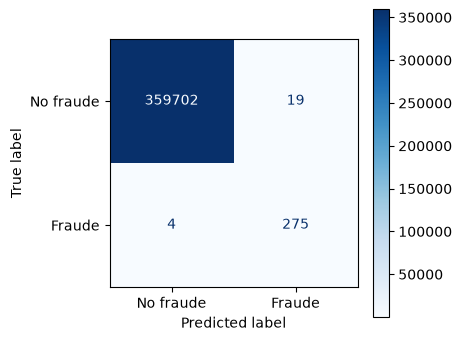

In [8]:
with mlflow.start_run(run_name="champion_xgboost_random_search"):
    mlflow.log_param("model", "XGBClassifier")
    mlflow.log_param("hpo_method", "random_search")
    mlflow.log_param("balancing_strategy", mejor_estrategia)
    for k, v in best_params.items():
        mlflow.log_param(k, v)

    # --- Evaluacion OFFLINE (holdout de referencia, step <= 400) ---
    proba_test = champion.predict_proba(X_test)[:, 1]
    preds_test = (proba_test >= 0.5).astype(int)
    offline_metrics = classification_metrics(y_test, preds_test, proba_test)
    log_classification_metrics("offline_", offline_metrics)
    print("OFFLINE:", offline_metrics)

    # --- Evaluacion ONLINE (produccion, step > 400) ---
    X_prod, y_prod = production[FEATURES], production[TARGET_COL]
    proba_prod = champion.predict_proba(X_prod)[:, 1]
    preds_prod = (proba_prod >= 0.5).astype(int)
    online_metrics = classification_metrics(y_prod, preds_prod, proba_prod)
    log_classification_metrics("online_", online_metrics)
    print("ONLINE:", online_metrics)

    mlflow.xgboost.log_model(champion, artifact_path="model")

    cm = confusion_matrix(y_test, preds_test)
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm, display_labels=["No fraude", "Fraude"]).plot(ax=ax, cmap="Blues")
    fig.savefig("../reports/confusion_matrix_offline.png", bbox_inches="tight")
    mlflow.log_artifact("../reports/confusion_matrix_offline.png")
    plt.show()

In [9]:
joblib.dump({"model": champion, "features": FEATURES}, MODEL_PATH)
print("Modelo guardado en", MODEL_PATH)

production = production.copy()
production["fraud_proba"] = champion.predict_proba(production[FEATURES])[:, 1]
production["fraud_pred"] = (production["fraud_proba"] >= 0.5).astype(int)
production.to_csv(PRODUCTION_DATA_PATH.parent / "production_scored.csv", index=False)
print("Produccion scoreada guardada para el notebook de monitoreo.")

# Guardamos tambien el holdout de referencia (X_test/y_test) ya scoreado.
# El notebook de monitoreo lo usa como baseline de desempeno "offline" --
# nunca se debe scorear el champion sobre TODO reference.csv para ese fin,
# porque incluye las filas de entrenamiento (X_train) y seria fuga de
# informacion (prediccion in-sample, artificialmente optimista).
reference_test_scored = X_test.copy()
reference_test_scored[TARGET_COL] = y_test.values
reference_test_scored["fraud_proba"] = proba_test
reference_test_scored["fraud_pred"] = preds_test
reference_test_scored.to_csv(PRODUCTION_DATA_PATH.parent / "reference_test_scored.csv", index=False)
print("Holdout de referencia (X_test) scoreado guardado para el notebook de monitoreo.")

Modelo guardado en D:\DataScienceResearchPeru\Machine_Learning_Engineering_2026_cohort_now\Proyecto_ML_Engineering_DSRP_III_2026_Fraud_Detection\artifacts\models\fraud_model.pkl


Produccion scoreada guardada para el notebook de monitoreo.


Holdout de referencia (X_test) scoreado guardado para el notebook de monitoreo.


## 2.5 Siguiente paso

- Ver experimentos: `mlflow ui --backend-store-uri ./mlruns` (desde la raiz del repo).
- Continuar con [`3.0-interpretabilidad.ipynb`](3.0-interpretabilidad.ipynb).